# IIMT Native: CSV → одна / две руки
Без ROS. `pip install "iimt-native[notebook]"` из проверенного wheel. По умолчанию используются **внешние TCP mock-процессы**, не реальные роботы.

CSV содержит время `t` (секунды) и `left_q1_rad…left_q6_rad`, `right_q1_rad…right_q6_rad`. Скорости/ускорения из CSV не используются и не придумываются. Подвод — отдельная ячейка с RRTConnect. Графики используют **UTC**, ошибка = фактическое − заданное. Timestamp измерения — получение ответа на ПК, не время энкодера. Упреждение изменяет отправку, не ось графика.

На настоящем стенде проверьте URDF/основания/workspace, аварийный останов и допустимость траектории. Mock не доказывает динамику или безопасность железа.

In [1]:
%matplotlib inline
from pathlib import Path
import time
import numpy as np
from iimt import Arm, Robot, Trajectory, ci05_scene
from iimt.mock import MockRobot
from iimt.plotting import plot_execution

DUAL = False
USE_MOCK = True
VIEWER = True  # True — отдельное 3D окно; нужен графический рабочий стол.
RUN_APPROACH = True
RUN_CSV = True
LEFT_IP, RIGHT_IP = "127.0.0.1","127.0.0.1"#"192.168.50.95", "192.168.50.163"
LEFT_PORT = RIGHT_PORT = 29999
COMMAND_HZ, READ_HZ = 125., 125.
ADVANCE_MS = [320., 320.]  # независимые калиброванные значения, не универсальные 330 мс.
START_DELAY_S = 3.0    # timestamp сообщения создаётся ПОСЛЕ collision preflight.
WORKSPACE_MARGINS = (.5, .5, .5, .5)  # X−, X+, Y−, Y+, метры.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data/trajectory_both_TimeGrid_30Hz.csv").exists())
CSV_PATH = ROOT / "data/trajectory_both_TimeGrid_30Hz.csv"
OUTPUT = ROOT / "results" / time.strftime("%Y%m%dT%H%M%SZ", time.gmtime())
scene = ci05_scene(dual=DUAL, margins=WORKSPACE_MARGINS)
trajectory = Trajectory.from_csv(CSV_PATH, scene.joint_names, arm="both" if DUAL else "left")
print(len(trajectory.times), "точек; длительность", trajectory.times[-1], "с")

121 точек; длительность 3.99999998850307 с


In [2]:
# Независимые mock-серверы. Контроллер знает только обычные IP и TCP-порты.
mocks = []
endpoints = [(LEFT_IP, LEFT_PORT), (RIGHT_IP, RIGHT_PORT)][:2 if DUAL else 1]
if USE_MOCK:
    for i in range(len(endpoints)):
        mock = MockRobot(positions=trajectory.positions[0, i*6:(i+1)*6].tolist()).start()
        mocks.append(mock)
    endpoints = [(mock.host, mock.port) for mock in mocks]
arms = [Arm(name=("left", "right")[i], ip=ip, port=port,
            joint_names=scene.joint_names[i*6:(i+1)*6], enable_motion=True,
            command_rate=COMMAND_HZ, read_rate=READ_HZ, advance_ms=ADVANCE_MS[i])
        for i, (ip, port) in enumerate(endpoints)]
robot = Robot(arms, scene=scene).connect(viewer=VIEWER)
robot.get_state()

{'arms': [{'name': 'left',
   'joint_names': ['shoulder_joint',
    'upper_arm_joint',
    'forearm_joint',
    'wrist_1_joint',
    'wrist_2_joint',
    'wrist_3_joint'],
   'positions': [0.0, -1.570796327, 0.0, -1.570796327, 0.0, 0.0],
   'velocities': [0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
   'stamp_unix_ns': 1793341770864693990,
   'received_monotonic_ns': 80897083555906,
   'age_s': 0.004549979,
   'read_duration_s': 0.000122684,
   'valid': True,
   'desired_positions': None,
   'goal_id': None,
   'start_unix_ns': None,
   'desired_stamp_unix_ns': None,
   'nominal_elapsed_s': None}],
 'active': False,
 'connected': True,
 'fault': ''}

## 1. Отдельный подвод к первой точке CSV через RRTConnect

Info:    RRTConnect: Starting planning with 1 states already in datastructure
Info:    RRTConnect: Created 4 states (2 start + 2 goal)
Info:    Solution found in 0.055197 seconds
{'goal_id': 1, 'status': 'succeeded', 'message': 'Trajectory completed; arm=left API_Clear skipped: protective-stop release not authorized; queue purge is NOT confirmed', 'start_unix_ns': 1793341783953476096}
{'left': {'samples': 381, 'rmse_rad': [0.0, 3.6731007774022066e-06, 0.0, 3.6731007774022066e-06, 0.0, 0.0], 'max_abs_rad': [0.0, 3.673205071441643e-06, 0.0, 3.673205071441643e-06, 0.0, 0.0]}}


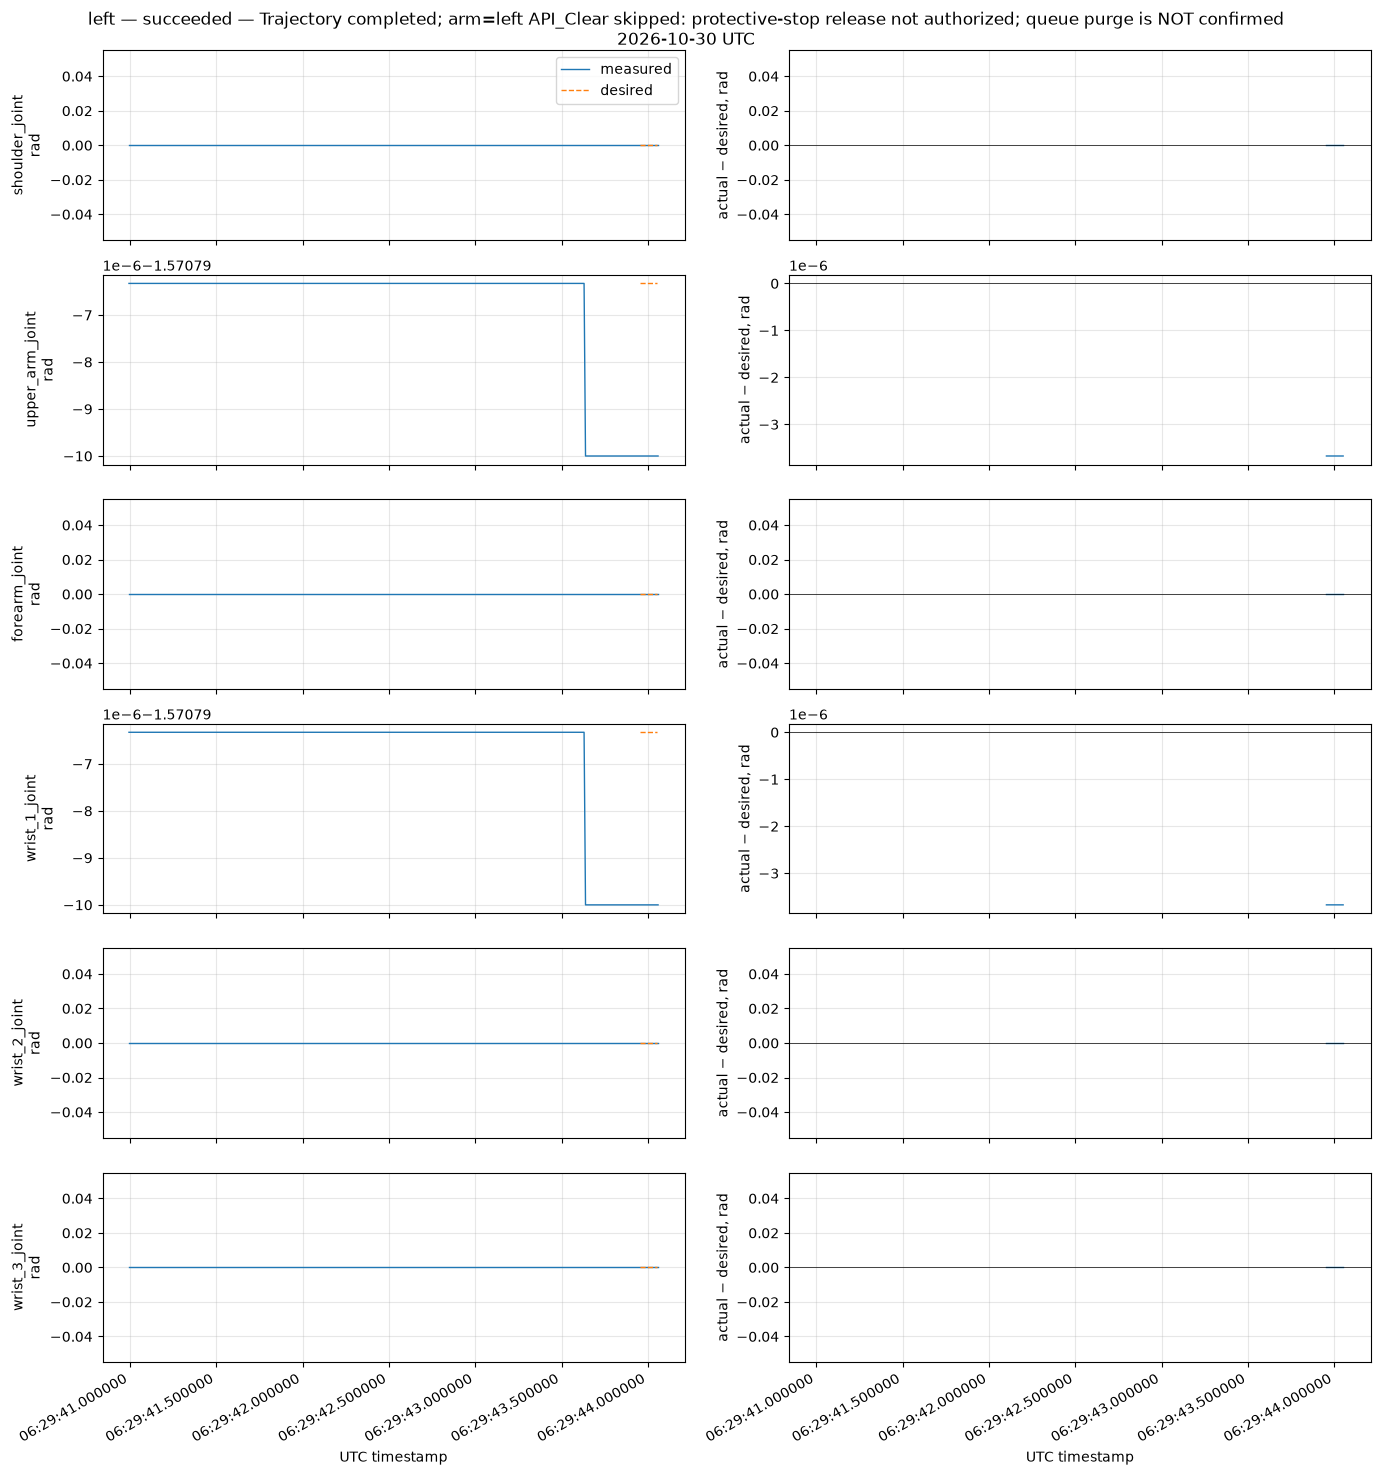

In [3]:
approach_execution = None
if RUN_APPROACH:
    try:
        approach = robot.plan(trajectory.positions[0], scale=.2)
        approach_execution = robot.execute_trajectory(approach, start_delay=START_DELAY_S)
        print(approach_execution.wait(approach.times[-1] + START_DELAY_S + 10))
    except Exception as error:
        print(type(error).__name__, error)
    finally:
        if approach_execution is not None:
            figures, metrics = plot_execution(approach_execution, OUTPUT / "approach")
            print(metrics)
else:
    print("Для подвода установите RUN_APPROACH=True и повторите эту ячейку.")

## 2. Выполнить именно CSV
Нет entry/lead-out и переназначения времени. Обе руки получают один `start_unix_ns`. Collision preflight дискретный, не непрерывная гарантия.

{'goal_id': 2, 'status': 'succeeded', 'message': 'Trajectory completed; arm=left API_Clear skipped: protective-stop release not authorized; queue purge is NOT confirmed', 'start_unix_ns': 1793341790348822016}
{'left': {'samples': 864, 'rmse_rad': [0.24449206214328964, 0.019170935292635517, 0.09821065119204349, 0.0594073860879377, 0.16340045141278417, 0.023763176646931904], 'max_abs_rad': [0.3351308083017581, 0.05930319163715536, 0.2591854307654121, 0.21016900584979226, 0.33454683924596, 0.08271047076664101]}}
{'arms': [{'name': 'left', 'ip': '127.0.0.1', 'port': 38029, 'command_rate': 125.0, 'read_rate': 125.0, 'windows_timer_resolution_ms': 1, 'allow_protective_stop_release': False, 'read_calls': 3296, 'read_timeouts': 0, 'read_errors': 0, 'sends': 595, 'missed_slots': 0, 'warnings': 0, 'last_read_duration': 0.000102836, 'max_read_duration': 0.000837643, 'last_send_duration': 2.1991e-05, 'max_send_duration': 9.9089e-05, 'last_send_interval': 0.007985737, 'max_send_interval': 0.0084815

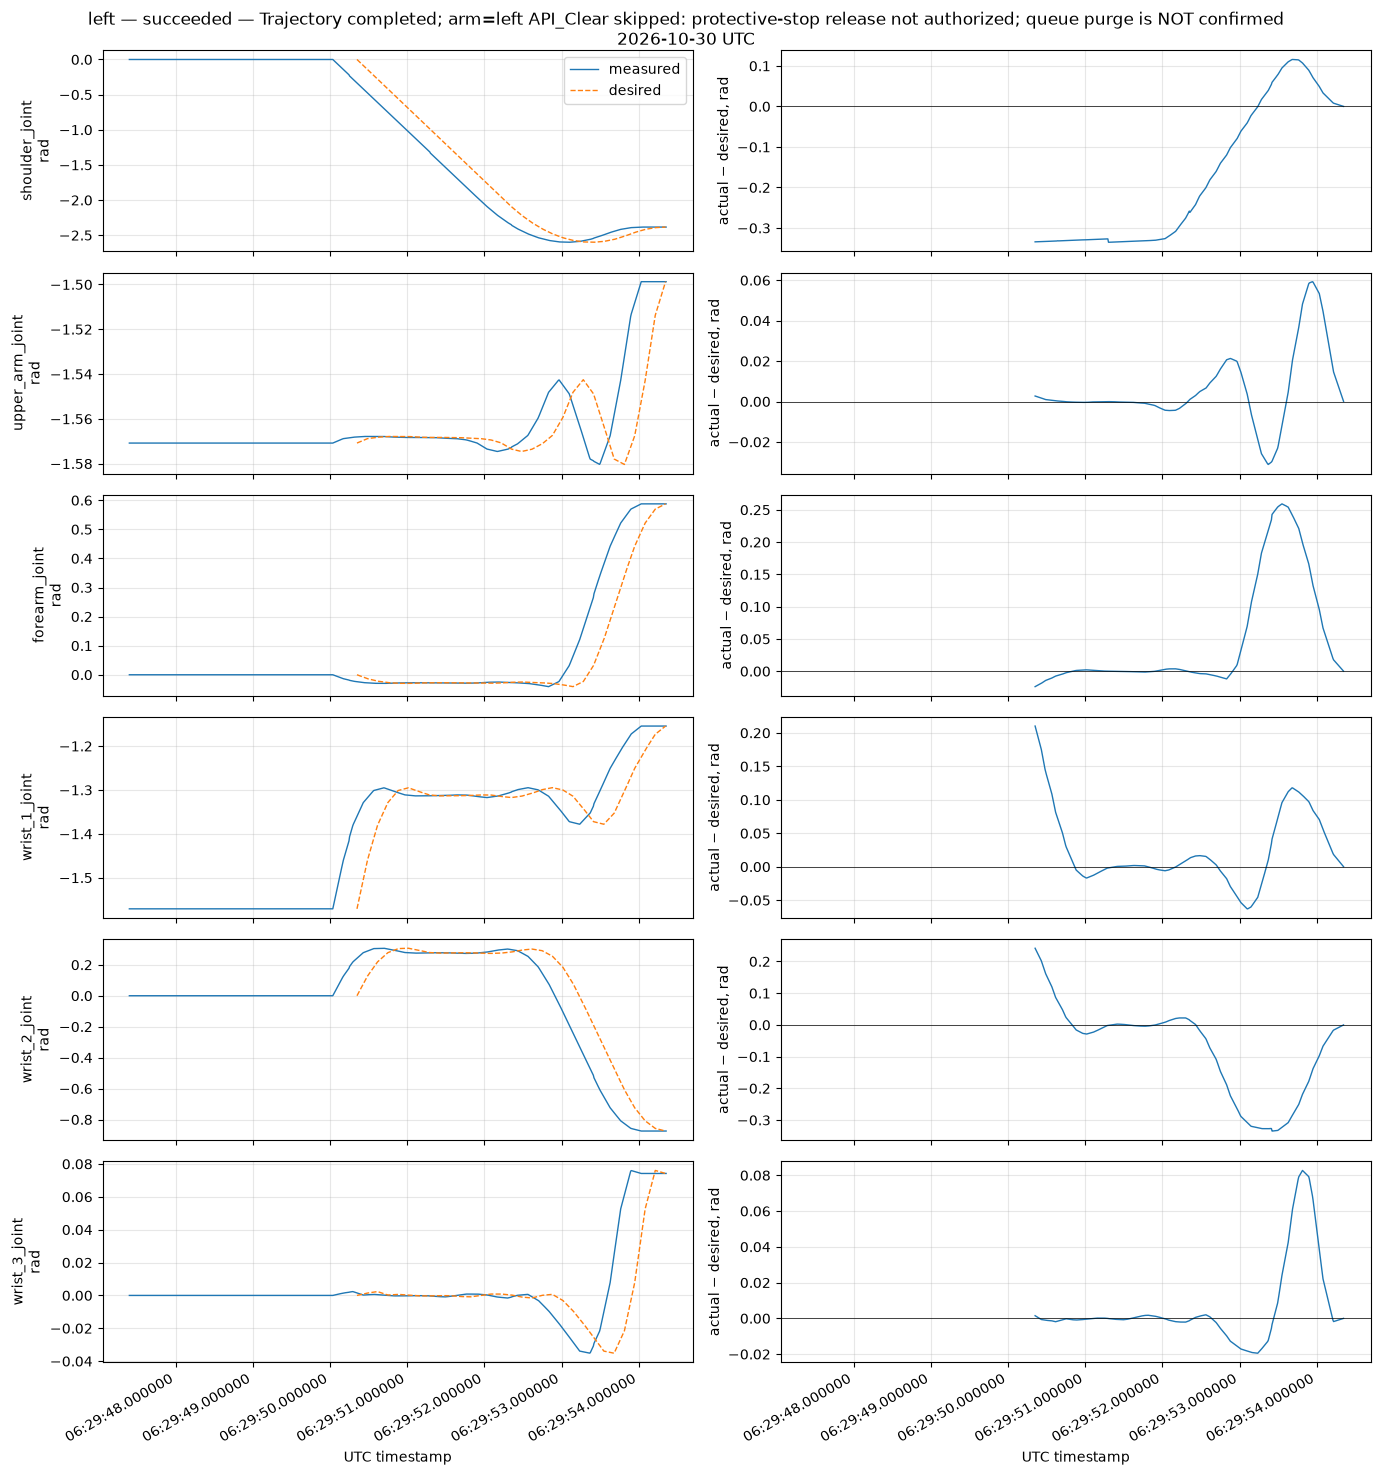

In [4]:
csv_execution = None
if RUN_CSV:
    try:
        csv_execution = robot.execute_trajectory(trajectory, start_delay=START_DELAY_S)
        print(csv_execution.wait(trajectory.times[-1] + START_DELAY_S + 10))
    except Exception as error:
        print(type(error).__name__, error)
    finally:
        if csv_execution is not None:
            figures, metrics = plot_execution(csv_execution, OUTPUT / "csv")
            print(metrics)
        print(robot.diagnostics())
else:
    print("Для выполнения установите RUN_CSV=True и повторите эту ячейку.")

## Дополнительно: случайная суставная цель, RRTConnect и явное выполнение

In [5]:
RUN_RANDOM = False
random_execution = None
if RUN_RANDOM:
    try:
        measured = np.concatenate([arm["positions"] for arm in robot.get_state()["arms"]])
        target = measured + np.random.default_rng().uniform(-.15, .15, len(measured))
        random_plan = robot.plan(target, scale=.2)  # невалидная цель отвергается.
        random_execution = robot.execute_trajectory(random_plan, start_delay=START_DELAY_S)
        print(random_execution.wait(random_plan.times[-1] + START_DELAY_S + 10))
    except Exception as error:
        print(type(error).__name__, error)
    finally:
        if random_execution is not None:
            plot_execution(random_execution, OUTPUT / "random")

In [6]:
# robot.cancel() — отдельная явная отмена активного выполнения.
robot.close()
for mock in mocks:
    mock.close()